## Introduction

Après avoir acquis des données expérimentales avec le logiciel LatisPro, il peut être intéressant de les exploiter dans Python, notamment pour bénéficier de ses nombreuses possibilités d’analyse numérique, réaliser des traitements plus poussés ou contourner certains problèmes de stabilité du logiciel.

Une solution consiste à exporter les données dans un fichier intermédiaire, au format CSV par exemple, puis à les importer dans Python. Bien que fonctionnelle, cette méthode nécessite plusieurs manipulations supplémentaires (choix du séparateur, du symbole de virgule, ...), qui peuvent être fastidieuses et sources d’erreurs.

L’objectif de cette page est de présenter une méthode permettant d’importer directement un fichier `.ltp` dans Python, sans passer par une étape d’exportation intermédiaire. Cette approche simplifie le traitement des données expérimentales et facilite l’automatisation des analyses.

J'en profite pour partager le super travail de Frédéric Legrand.
La bibliothèque [`pycanum`](https://www.f-legrand.fr/scidoc/docmml/sciphys/caneurosmart/interpy/interpy.html) permet de commander directement la centrale SysamSP5 de Eurosmart en Python.

## Implémentation Python

In [83]:
import numpy as np
from lxml import etree

class ReadLTP():
    def __init__(self, nom):
        self.nom = nom

        # Ouverture du fichier
        with open( nom, encoding='utf16') as f:
            lignes = f.readlines()

        # Il faut ajouter des balises global, sinon Python ne le détecte pas comme un fichier XML lisible
        data = '<file>'+''.join(lignes)+'</file>'
        parser = etree.XMLParser(recover=True)
        tree = etree.fromstring(data, parser=parser)
    
        courbes = tree.find('BLOC-COURBES').find('LESCOURBES').find('C')
    
        self.courbes_data = []
        print( 'Courbes disponibles :')
        print( f' num |   x   |   y' )
        print( '-'*26 )
        for i in range(len( courbes )):
            d = self.load_curve( courbes, i )
            xlabel = d['xlabel']
            ylabel = d['ylabel']
            print( f'{i:4d} | {xlabel:5s} | {ylabel:10s}' )
            self.courbes_data.append( d )
            
    def courbe( self, i ):
        return self.courbes_data[i]

    def load_courbe_1D(self, curve):
        data_hex = curve.find('DONNEES').text
        label = curve.find('NOM').text
        data = np.frombuffer( bytes.fromhex(data_hex), dtype='>f8' )
        return data, label 
    
    def load_curve(self, courbes, i):
        C = courbes.getchildren()[i]
        x, xl = self.load_courbe_1D(C.find('DATAX').getchildren()[0])
        y, yl = self.load_courbe_1D(C.find('DATAY').getchildren()[0])
        return {'x':x, 'y':y, 'xlabel':xl, 'ylabel':yl}


**Exemple d'utilisation :**

In [84]:
name = 'test.ltp'
data = ReadLTP( name )

Courbes disponibles :
 num |   x   |   y
--------------------------
   0 | Temps | EA26_D    
   1 | Temps | EA37_D    
   2 | Temps | EA26_D    
   3 | Temps | EA37_D    
   4 | Temps | EA26_D    
   5 | Temps | EA37_D    
   6 | Temps | EA26_D    
   7 | Temps | EA37_D    


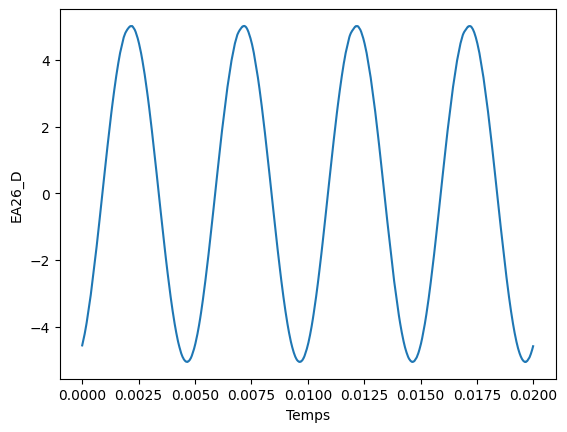

In [85]:
import matplotlib.pyplot as plt

c = data.courbe(6)

plt.plot( c['x'], c['y'] )
plt.xlabel( c["xlabel"] )
plt.ylabel( c["ylabel"] )
plt.show()

## Détails techniques de la conversion

Lorsqu'on ouvre un fichier `.ltp` avec un éditeur de texte, on constate que son contenu est organisé selon une structure de type XML. Les balises, dont les noms sont souvent explicites, permettent notamment d'identifier les courbes enregistrées, leurs abscisses et leurs ordonnées.

Cependant, les valeurs numériques ne sont pas directement écrites sous forme décimale. Elles sont stockées sous forme d'une chaîne de caractères hexadécimaux dans la balise `<DONNEES>`. Il est donc nécessaire de décoder cette chaîne pour retrouver les nombres et les exploiter dans Python.

**Extrait d'un fichier `.ltp` :**

```xml
<BLOC-COURBES TYPE="TCourbes2D">
 <LESCOURBES>
  <C Nb="8">
   <C0 TYPE="TCourbe2D">
    <IDFTEXT>{AD036828-0AB3-4B99-9773-345520531A96}</IDFTEXT>
    <C3D_TEXT></C3D_TEXT>
    <TYPEABSISSECALCUL>0</TYPEABSISSECALCUL>
    <DATAX>
     <DonneesX TYPE="TCourbe1D">
      <IDFTEXT>{618BF85F-CE5D-47B6-A414-08021CE73EB5}</IDFTEXT>
      <FORMULE></FORMULE>
      <COURBEX>True</COURBEX>
      <NBDATA>2000</NBDATA>
      <DONNEES>00000000000000003F1A36E2EB...
```

La balise `<NBDATA>` indique ici que la courbe contient 2000 valeurs. La balise `<DONNEES>` contient leur représentation hexadécimale. 
On constate facilement que la balise `<DONNEES>` contient 16$\cdot$`<NBDATA>` caractères.
Ce qui nous indique que les points sont représentés par 16 caractères hexadécimaux, c'est-à-dire 8 octets ou encore 64 bits.
Ce sont donc des nombres flottants en double précision, correspondant au type `float64` de NumPy.

La chaîne peut alors être découpée en blocs successifs de 16 caractères, chacun correspondant à un nombre flottant :

$$
\cdots\quad
\underbrace{\mathtt{3FC98C7E28240B78}}_{\text{flottant 1}}
\quad
\underbrace{\mathtt{3FC98FC504816F00}}_{\text{flottant 2}}
\quad
\underbrace{\mathtt{3FC9930BE0DED289}}_{\text{flottant 3}}
\quad \cdots
$$

Chaque bloc contient 16 caractères, soit 8 octets. Il faut maintenant interpréter correctement ces octets pour retrouver les valeurs numériques.

Deux conventions existent pour le stockage des flottants, c'est la convention de [boutisme](https://fr.wikipedia.org/wiki/Boutisme).
On parle de *gros-boutiste* ou *petit-boutiste* (en anglais *big-endian* ou *little-endian*) :

- **gros-boutiste :** l'octet de poids fort est placé en premier.
- **petit-boutiste :** l'octet de poids faible est placé en premier.

Dans le cas des fichiers Latispro, c'est la convention gros-boutiste qui est employée.

Une fois la chaîne hexadécimale extraite de la balise `<DONNEES>`, Python permet de la convertir en octets, puis en tableau de nombres flottants à l'aide de NumPy.

1. La méthode `bytes.fromhex(...)` transforme la chaîne hexadécimale en une séquence d'octets.
2. La fonction `np.frombuffer(..., dtype='>f8')` interprète ensuite ces octets selon le type numérique et l'ordre des octets spécifiés. L'option `'>f8'` indique que la conversion doit être faite en utilisant des flottants double-précision (`f8`) en convention gros-boutiste `'>'`, conformement à l'aide `numpy` sur les types (voir [np.dtype](https://numpy.org/devdocs//reference/arrays.dtypes.html)).

**Exemple :**

In [86]:
import numpy as np

# Exemple de chaîne hexadécimale
donnees_hex = "00000000000000003FC98C7E28240B78"
# Conversion de l'hexadécimal en octets
donnees_binaires = bytes.fromhex(donnees_hex)
# Interprétation en flottants 64 bits, ordre little-endian
valeurs = np.frombuffer(donnees_binaires, dtype=">f8")
print(valeurs)

[0.     0.1996]


## Début de réflexion pour la conversion inverse, générateur de `.lpt`

J'ai débuté une réflexion pour réaliser un code python permet de générer des fichiers `.ltp` directement lisible par LatisPro.
L'interêt est plus limité, mais on peut imaginer générer des fichiers de données factices sur lesquels les étudiants peuvent travailler sans avoir à faire d'acquisition.

In [87]:
def float_to_hex( Val ):
    """Fonction qui traduit un scalaire en une chaîne de caractère lisible par LatisPro"""
    # Conversion de scalaire en float
    A = np.array( Val ).astype( '>f8' )
    # Conversion en suite de byte ( suite inversée pour LatisPro )
    B = A.tobytes('C')
    # Chaîne de caractère compréhensible par LatisPro
    return  ''.join([f'{hex(b)[2:]:0>2}'.upper() for b in B])

float_to_hex( [0, 0.1996] )    

'00000000000000003FC98C7E28240B78'